In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR="/content/drive/MyDrive/CrisisWeave_Project"

DATASET_DIR=os.path.join(PROJECT_DIR,"01_Dataset")
MODEL_DIR=os.path.join(PROJECT_DIR,"03_Models")
RESULT_DIR=os.path.join(PROJECT_DIR,"04_Results")

In [ ]:
SEG_DIR=os.path.join(DATASET_DIR,"Segmentation")

IMAGE_DIR=os.path.join(SEG_DIR,"Images")
MASK_DIR=os.path.join(SEG_DIR,"Masks")

SEG_MODEL_DIR=os.path.join(MODEL_DIR,"SegFormer")

SEG_RESULT_DIR=os.path.join(RESULT_DIR,"SegFormer")

folders=[
    SEG_DIR,
    IMAGE_DIR,
    MASK_DIR,
    SEG_MODEL_DIR,
    SEG_RESULT_DIR
]

for folder in folders:
    os.makedirs(folder,exist_ok=True)

print("Folders Created Successfully")

Folders Created Successfully


Import Libraries

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

Set Random Seed

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

Project Paths

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/CrisisWeave_Project"

DATASET_DIR = os.path.join(PROJECT_DIR, "01_Dataset", "Segmentation")

IMAGE_DIR = os.path.join(DATASET_DIR, "Images")
MASK_DIR = os.path.join(DATASET_DIR, "Masks")

MODEL_DIR = os.path.join(PROJECT_DIR, "03_Models", "SegFormer")
RESULTS_DIR = os.path.join(PROJECT_DIR, "04_Results", "SegFormer")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

Dataset Verification

In [ ]:
image_files = sorted(os.listdir(IMAGE_DIR))
mask_files = sorted(os.listdir(MASK_DIR))

print("Total Images :", len(image_files))
print("Total Masks  :", len(mask_files))

missing_masks = []
missing_images = []

for img in image_files:
    if img not in mask_files:
        missing_masks.append(img)

for mask in mask_files:
    if mask not in image_files:
        missing_images.append(mask)

print("\nMissing Masks :", len(missing_masks))
print("Missing Images:", len(missing_images))

Total Images : 3402
Total Masks  : 3402

Missing Masks : 0
Missing Images: 0


Train / Validation / Test Split

In [ ]:
from sklearn.model_selection import train_test_split
import shutil
import os

# Split image filenames
image_files = sorted(os.listdir(IMAGE_DIR))

train_files, test_files = train_test_split(
    image_files,
    test_size=0.15,
    random_state=42
)

train_files, val_files = train_test_split(
    train_files,
    test_size=0.1765,   # Gives 70/15/15 overall
    random_state=42
)

# Create folders
for split in ["Train", "Validation", "Test"]:
    os.makedirs(os.path.join(DATASET_DIR, split, "Images"), exist_ok=True)
    os.makedirs(os.path.join(DATASET_DIR, split, "Masks"), exist_ok=True)

# Function to copy image-mask pairs
def copy_files(file_list, split):
    for file in file_list:
        shutil.copy2(
            os.path.join(IMAGE_DIR, file),
            os.path.join(DATASET_DIR, split, "Images", file)
        )

        shutil.copy2(
            os.path.join(MASK_DIR, file),
            os.path.join(DATASET_DIR, split, "Masks", file)
        )

# Copy files
copy_files(train_files, "Train")
copy_files(val_files, "Validation")
copy_files(test_files, "Test")

print("Dataset split completed successfully!")
print(f"Train      : {len(train_files)}")
print(f"Validation : {len(val_files)}")
print(f"Test       : {len(test_files)}")

Dataset split completed successfully!
Train      : 2380
Validation : 511
Test       : 511


In [ ]:
!pip install -q transformers
!pip install -q evaluate
!pip install -q datasets
!pip install -q accelerate

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

from transformers import SegformerImageProcessor
from transformers import SegformerForSemanticSegmentation

from torchvision.transforms import functional as TF

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


Define Dataset Paths

In [ ]:
TRAIN_IMAGE_DIR = os.path.join(DATASET_DIR, "Train", "Images")
TRAIN_MASK_DIR = os.path.join(DATASET_DIR, "Train", "Masks")

VAL_IMAGE_DIR = os.path.join(DATASET_DIR, "Validation", "Images")
VAL_MASK_DIR = os.path.join(DATASET_DIR, "Validation", "Masks")

TEST_IMAGE_DIR = os.path.join(DATASET_DIR, "Test", "Images")
TEST_MASK_DIR = os.path.join(DATASET_DIR, "Test", "Masks")

Load SegFormer Processor

In [ ]:
processor = SegformerImageProcessor(
    do_resize=True,
    size={"height":512, "width":512},
    do_normalize=True
)

Custom Dataset Class

In [ ]:
class FloodDataset(Dataset):

    def __init__(self, image_dir, mask_dir, processor):

        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.processor = processor

        self.images = sorted(os.listdir(image_dir))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_name = self.images[idx]

        image = Image.open(
            os.path.join(self.image_dir, image_name)
        ).convert("RGB")

        mask = Image.open(
            os.path.join(self.mask_dir, image_name)
        ).convert("L")

        mask = np.array(mask)
        mask = (mask > 0).astype(np.uint8)

        encoded = self.processor(
            images=image,
            segmentation_maps=mask,
            return_tensors="pt"
        )

        pixel_values = encoded["pixel_values"].squeeze()
        labels = encoded["labels"].squeeze()

        return {
            "pixel_values": pixel_values,
            "labels": labels
        }

Create Datasets

In [ ]:
train_dataset = FloodDataset(
    TRAIN_IMAGE_DIR,
    TRAIN_MASK_DIR,
    processor
)

val_dataset = FloodDataset(
    VAL_IMAGE_DIR,
    VAL_MASK_DIR,
    processor
)

test_dataset = FloodDataset(
    TEST_IMAGE_DIR,
    TEST_MASK_DIR,
    processor
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 2380
Validation: 511
Test: 511


Create DataLoaders

In [ ]:
BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 595
Validation batches: 128
Test batches: 128


Load Pretrained SegFormer-B0

In [ ]:
model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512",
    num_labels=2,
    ignore_mismatched_sizes=True
)

model.to(device)

print("SegFormer-B0 loaded successfully!")

config.json:   0%|          | 0.00/6.88k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.0MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


SegFormer-B0 loaded successfully!


Define Optimizer

In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4
)

print("Optimizer initialized.")

Optimizer initialized.


Verify One Batch

In [ ]:
batch = next(iter(train_loader))

print("Pixel Values Shape :", batch["pixel_values"].shape)
print("Labels Shape       :", batch["labels"].shape)

Pixel Values Shape : torch.Size([4, 3, 512, 512])
Labels Shape       : torch.Size([4, 512, 512])


Training Configuration

In [ ]:
NUM_EPOCHS = 20

train_losses = []
val_losses = []

Training Loop

In [ ]:
from tqdm import tqdm
import torch

for epoch in range(NUM_EPOCHS):

    # -----------------------------
    # Training
    # -----------------------------
    model.train()
    train_loss = 0

    train_bar = tqdm(train_loader)

    for batch in train_bar:

        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            pixel_values=pixel_values,
            labels=labels
        )

        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        train_bar.set_description(
            f"Epoch {epoch+1}/{NUM_EPOCHS}"
        )
        train_bar.set_postfix(
            loss=loss.item()
        )

    avg_train_loss = train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # -----------------------------
    # Validation
    # -----------------------------
    model.eval()
    val_loss = 0

    with torch.no_grad():

        for batch in val_loader:

            pixel_values = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                pixel_values=pixel_values,
                labels=labels
            )

            val_loss += outputs.loss.item()

    avg_val_loss = val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch+1}/{NUM_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Validation Loss: {avg_val_loss:.4f}"
    )

Epoch 1/20: 100%|██████████| 595/595 [03:04<00:00,  3.23it/s, loss=0.174]


Epoch 1/20 | Train Loss: 0.2324 | Validation Loss: 0.1808


Epoch 2/20: 100%|██████████| 595/595 [02:57<00:00,  3.35it/s, loss=0.157]


Epoch 2/20 | Train Loss: 0.1773 | Validation Loss: 0.1644


Epoch 3/20: 100%|██████████| 595/595 [02:58<00:00,  3.34it/s, loss=0.107]


Epoch 3/20 | Train Loss: 0.1604 | Validation Loss: 0.1552


... (30 outputs left out)

Epoch 19/20: 100%|██████████| 595/595 [02:52<00:00,  3.44it/s, loss=0.118]


Epoch 19/20 | Train Loss: 0.1007 | Validation Loss: 0.1125


Epoch 20/20: 100%|██████████| 595/595 [02:53<00:00,  3.43it/s, loss=0.0812]


Epoch 20/20 | Train Loss: 0.0988 | Validation Loss: 0.1103


In [ ]:
MODEL_SAVE_PATH = os.path.join(
    MODEL_DIR,
    "SegFormer_B0_FloodSegmentation"
)

os.makedirs(MODEL_SAVE_PATH, exist_ok=True)

model.save_pretrained(MODEL_SAVE_PATH)
processor.save_pretrained(MODEL_SAVE_PATH)

print("Model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!


In [ ]:
import os

print(os.listdir(MODEL_SAVE_PATH))

['config.json', 'model.safetensors', 'preprocessor_config.json']


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

from transformers import (
    SegformerImageProcessor,
    SegformerForSemanticSegmentation
)

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [5]:
PROJECT_DIR = "/content/drive/MyDrive/CrisisWeave_project"

DATASET_DIR = os.path.join(PROJECT_DIR, "01_Dataset", "Segmentation")
MODEL_DIR   = os.path.join(PROJECT_DIR, "03_Models", "SegFormer")
RESULT_DIR  = os.path.join(PROJECT_DIR, "04_Results", "Segmentation")

os.makedirs(RESULT_DIR, exist_ok=True)

Load Saved SegFormer Model

In [6]:
MODEL_PATH = "/content/drive/MyDrive/CrisisWeave_Project/03_Models/SegFormer/SegFormer_B0_FloodSegmentation"

processor = SegformerImageProcessor.from_pretrained(
    MODEL_PATH,
    local_files_only=True
)

model = SegformerForSemanticSegmentation.from_pretrained(
    MODEL_PATH,
    local_files_only=True
)

model.to(device)
model.eval()

print("✅ SegFormer model loaded successfully!")

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

✅ SegFormer model loaded successfully!


In [7]:
PROJECT_DIR = "/content/drive/MyDrive/CrisisWeave_Project"

DATASET_DIR = os.path.join(PROJECT_DIR, "01_Dataset", "Segmentation")
RESULT_DIR  = os.path.join(PROJECT_DIR, "04_Results", "Segmentation")

TEST_IMAGE_DIR = os.path.join(DATASET_DIR, "Test", "Images")
TEST_MASK_DIR  = os.path.join(DATASET_DIR, "Test", "Masks")

os.makedirs(RESULT_DIR, exist_ok=True)

print(TEST_IMAGE_DIR)
print(TEST_MASK_DIR)

/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/Segmentation/Test/Images
/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/Segmentation/Test/Masks


Recreate the Processor

In [8]:
processor = SegformerImageProcessor(
    do_resize=True,
    size={"height": 512, "width": 512},
    do_normalize=True
)

Test Dataset Class

In [9]:
class FloodDataset(torch.utils.data.Dataset):

    def __init__(self, image_dir, mask_dir, processor):

        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.processor = processor

        self.images = sorted(os.listdir(image_dir))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_name = self.images[idx]

        image = Image.open(
            os.path.join(self.image_dir, image_name)
        ).convert("RGB")

        mask = Image.open(
            os.path.join(self.mask_dir, image_name)
        ).convert("L")

        mask = np.array(mask)
        mask = (mask > 0).astype(np.uint8)

        encoded = self.processor(
            images=image,
            segmentation_maps=mask,
            return_tensors="pt"
        )

        return {
            "pixel_values": encoded["pixel_values"].squeeze(),
            "labels": encoded["labels"].squeeze()
        }

Create Test Dataset & DataLoader

In [10]:
test_dataset = FloodDataset(
    TEST_IMAGE_DIR,
    TEST_MASK_DIR,
    processor
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False
)

print("Test Images :", len(test_dataset))
print("Test Batches:", len(test_loader))

Test Images : 510
Test Batches: 128


Install Metrics Library

In [11]:
!pip install -q torchmetrics

Import Required Libraries

In [12]:
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

In [13]:
from PIL import Image
import os

bad_files = []

for f in sorted(os.listdir(TEST_IMAGE_DIR)):
    try:
        img = Image.open(os.path.join(TEST_IMAGE_DIR, f))
        img.verify()
    except Exception:
        bad_files.append(f)

print("Bad files:", len(bad_files))
print(bad_files)

Bad files: 0
[]


Remove the Corrupted Image

In [14]:
import os

bad_image = "aug_147_1679.png"

image_path = os.path.join(TEST_IMAGE_DIR, bad_image)
mask_path = os.path.join(TEST_MASK_DIR, bad_image)

if os.path.exists(image_path):
    os.remove(image_path)
    print("✅ Removed image:", image_path)

if os.path.exists(mask_path):
    os.remove(mask_path)
    print("✅ Removed corresponding mask:", mask_path)

Verify

In [15]:
print("Test Images :", len(os.listdir(TEST_IMAGE_DIR)))
print("Test Masks  :", len(os.listdir(TEST_MASK_DIR)))

Test Images : 510
Test Masks  : 510


Recreate Dataset & DataLoader

In [16]:
test_dataset = FloodDataset(
    TEST_IMAGE_DIR,
    TEST_MASK_DIR,
    processor
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False
)

print("Dataset Size:", len(test_dataset))

Dataset Size: 510


Evaluation

In [17]:
import torch
import torch.nn.functional as F

model.eval()

total_intersection = 0
total_union = 0

total_pred = 0
total_gt = 0

correct_pixels = 0
total_pixels = 0

tp = 0
fp = 0
fn = 0

with torch.no_grad():

    for batch in test_loader:

        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(pixel_values=pixel_values)

        logits = F.interpolate(
            outputs.logits,
            size=labels.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        preds = torch.argmax(logits, dim=1)

        pred = preds.bool()
        gt = labels.bool()

        intersection = (pred & gt).sum().item()
        union = (pred | gt).sum().item()

        total_intersection += intersection
        total_union += union

        total_pred += pred.sum().item()
        total_gt += gt.sum().item()

        correct_pixels += (pred == gt).sum().item()
        total_pixels += pred.numel()

        tp += intersection
        fp += (pred & ~gt).sum().item()
        fn += (~pred & gt).sum().item()

Final Metrics

In [18]:
iou = total_intersection / (total_union + 1e-6)

dice = (2 * total_intersection) / (
    total_pred + total_gt + 1e-6
)

pixel_accuracy = correct_pixels / total_pixels

precision = tp / (tp + fp + 1e-6)

recall = tp / (tp + fn + 1e-6)

f1 = (2 * precision * recall) / (
    precision + recall + 1e-6
)

print("=" * 50)
print(f"IoU            : {iou:.4f}")
print(f"Dice Score     : {dice:.4f}")
print(f"Pixel Accuracy : {pixel_accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"F1 Score       : {f1:.4f}")
print("=" * 50)

IoU            : 0.9030
Dice Score     : 0.9490
Pixel Accuracy : 0.9549
Precision      : 0.9569
Recall         : 0.9412
F1 Score       : 0.9490


Import Libraries

In [19]:
import random
import matplotlib.pyplot as plt

Prediction Visualization

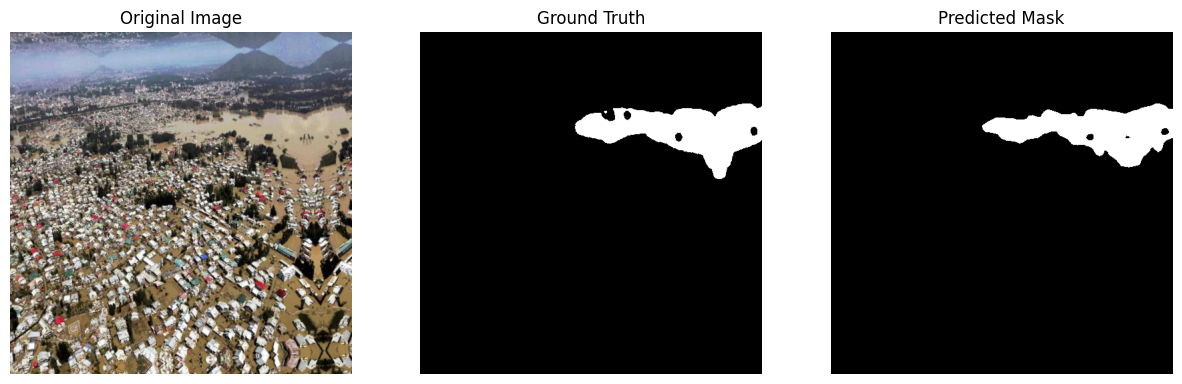

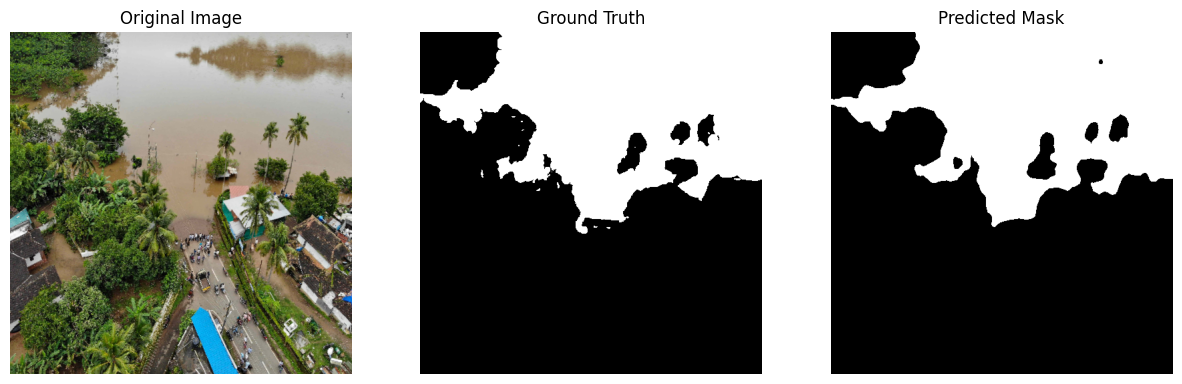

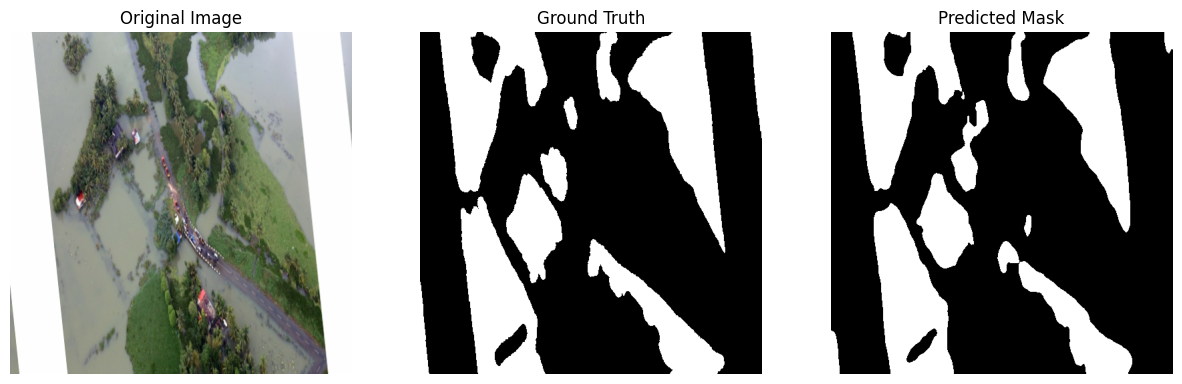

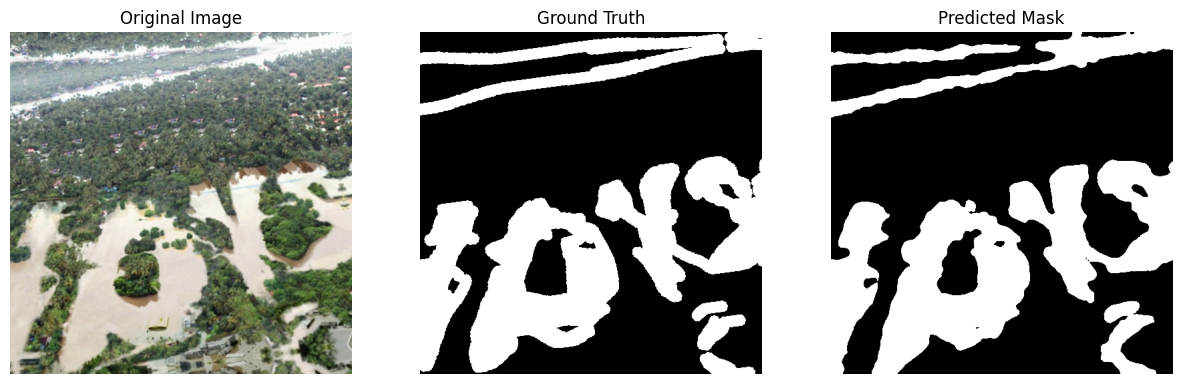

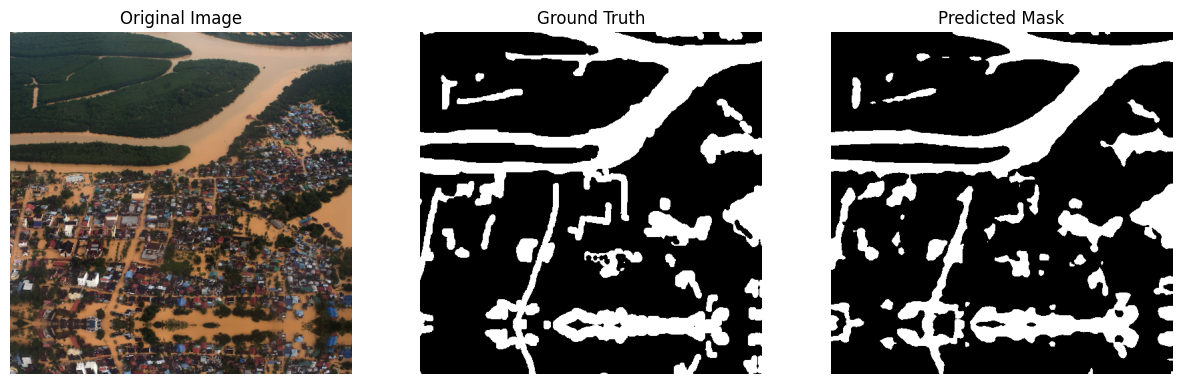

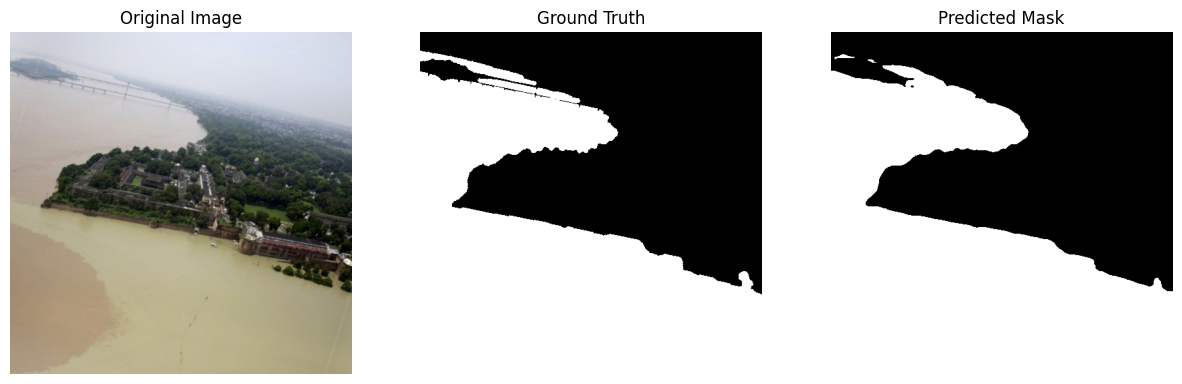

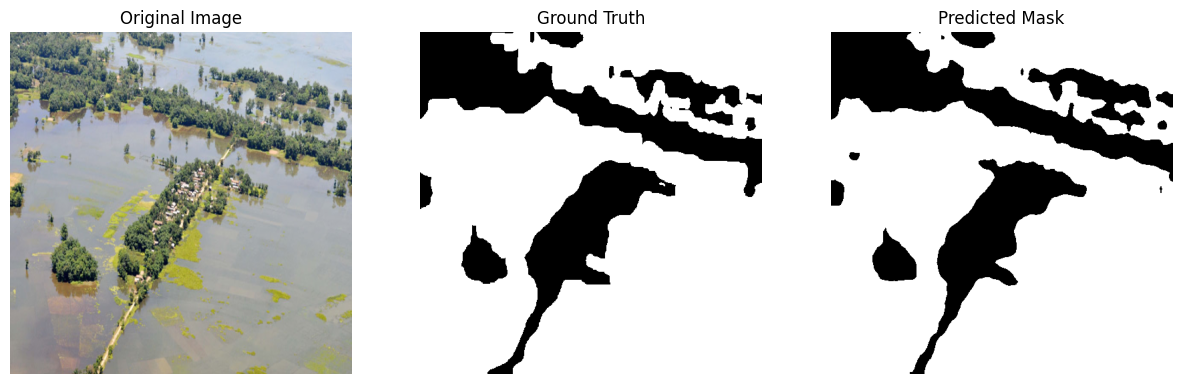

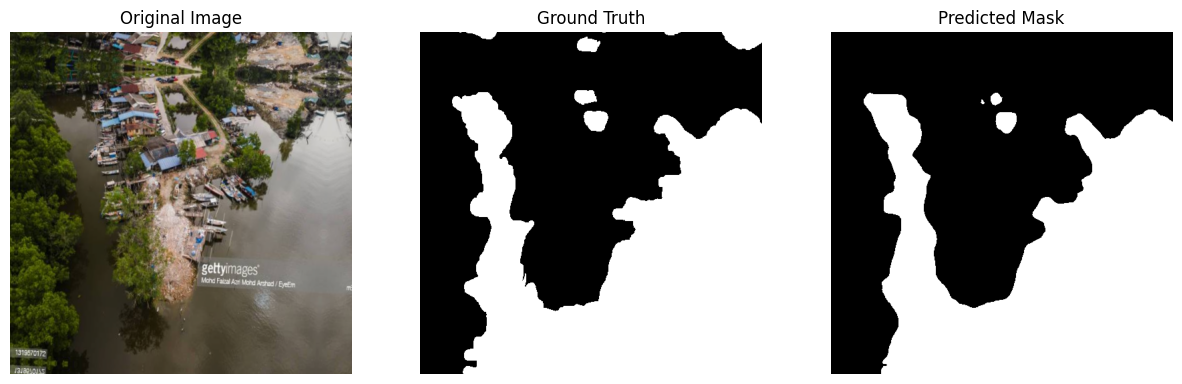

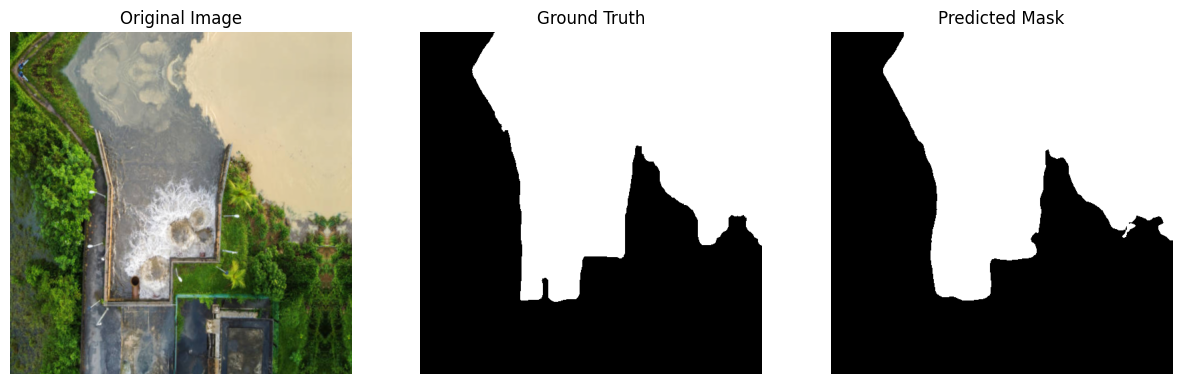

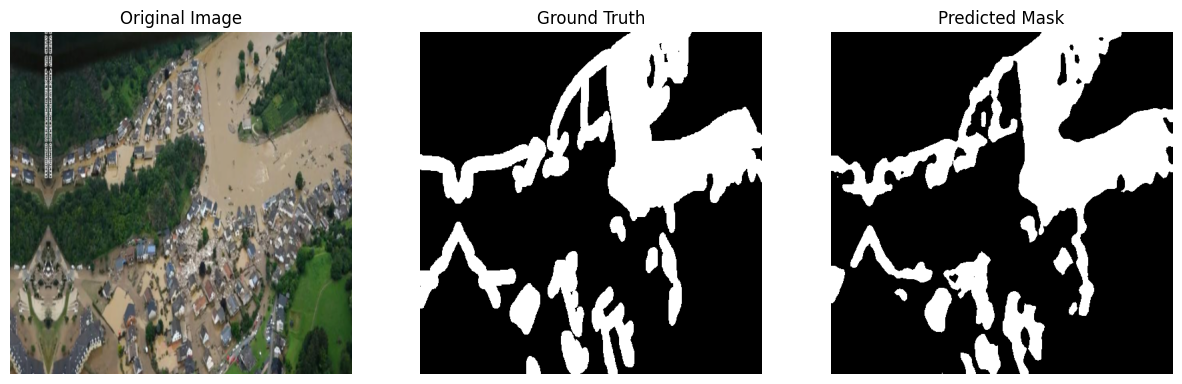

In [20]:
NUM_IMAGES = 10

indices = random.sample(range(len(test_dataset)), NUM_IMAGES)

model.eval()

for idx in indices:

    sample = test_dataset[idx]

    pixel_values = sample["pixel_values"].unsqueeze(0).to(device)
    ground_truth = sample["labels"].numpy()

    with torch.no_grad():

        outputs = model(pixel_values=pixel_values)

    logits = outputs.logits

    logits = F.interpolate(
        logits,
        size=ground_truth.shape,
        mode="bilinear",
        align_corners=False
    )

    prediction = torch.argmax(logits, dim=1).squeeze().cpu().numpy()

    image = pixel_values.squeeze().permute(1,2,0).cpu().numpy()

    image = image * processor.image_std + processor.image_mean
    image = np.clip(image,0,1)

    plt.figure(figsize=(15,5))

    plt.subplot(1,3,1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(ground_truth,cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(prediction,cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.show()

Save Prediction Images

In [21]:
import os

SAVE_DIR = os.path.join(
    RESULT_DIR,
    "Prediction_Visualization"
)

os.makedirs(SAVE_DIR, exist_ok=True)

model.eval()

NUM_IMAGES = 20

indices = random.sample(range(len(test_dataset)), NUM_IMAGES)

for count, idx in enumerate(indices):

    sample = test_dataset[idx]

    pixel_values = sample["pixel_values"].unsqueeze(0).to(device)
    ground_truth = sample["labels"].numpy()

    with torch.no_grad():
        outputs = model(pixel_values=pixel_values)

    logits = F.interpolate(
        outputs.logits,
        size=ground_truth.shape,
        mode="bilinear",
        align_corners=False
    )

    prediction = torch.argmax(logits, dim=1).squeeze().cpu().numpy()

    image = pixel_values.squeeze().permute(1,2,0).cpu().numpy()
    image = image * processor.image_std + processor.image_mean
    image = np.clip(image,0,1)

    plt.figure(figsize=(15,5))

    plt.subplot(1,3,1)
    plt.imshow(image)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(ground_truth,cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(prediction,cmap="gray")
    plt.title("Prediction")
    plt.axis("off")

    plt.savefig(
        os.path.join(SAVE_DIR, f"Prediction_{count+1}.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

print("✅ Saved prediction visualizations to:", SAVE_DIR)

✅ Saved prediction visualizations to: /content/drive/MyDrive/CrisisWeave_Project/04_Results/Segmentation/Prediction_Visualization


Generate Flood Coverage for Every Test Image

In [22]:
import pandas as pd

results = []

model.eval()

with torch.no_grad():

    for idx in range(len(test_dataset)):

        sample = test_dataset[idx]

        pixel_values = sample["pixel_values"].unsqueeze(0).to(device)

        outputs = model(pixel_values=pixel_values)

        logits = F.interpolate(
            outputs.logits,
            size=sample["labels"].shape,
            mode="bilinear",
            align_corners=False
        )

        prediction = torch.argmax(logits, dim=1).squeeze().cpu().numpy()

        flood_pixels = np.sum(prediction == 1)

        total_pixels = prediction.size

        flood_percentage = (flood_pixels / total_pixels) * 100

        results.append({
            "Image": test_dataset.images[idx],
            "FloodPixels": int(flood_pixels),
            "TotalPixels": int(total_pixels),
            "FloodCoverage(%)": round(flood_percentage, 2)
        })

coverage_df = pd.DataFrame(results)

coverage_df.head()

,Image,FloodPixels,TotalPixels,FloodCoverage(%)
0,1.png,70641,262144,26.95
1,1012.png,82054,262144,31.30
2,1015.png,151394,262144,57.75
3,1024.png,87189,262144,33.26
4,1028.png,11228,262144,4.28


Save Flood Coverage CSV

In [23]:
coverage_path = os.path.join(
    RESULT_DIR,
    "Flood_Coverage.csv"
)

coverage_df.to_csv(
    coverage_path,
    index=False
)

print("Saved to:")
print(coverage_path)

Saved to:
/content/drive/MyDrive/CrisisWeave_Project/04_Results/Segmentation/Flood_Coverage.csv


Coverage Distribution

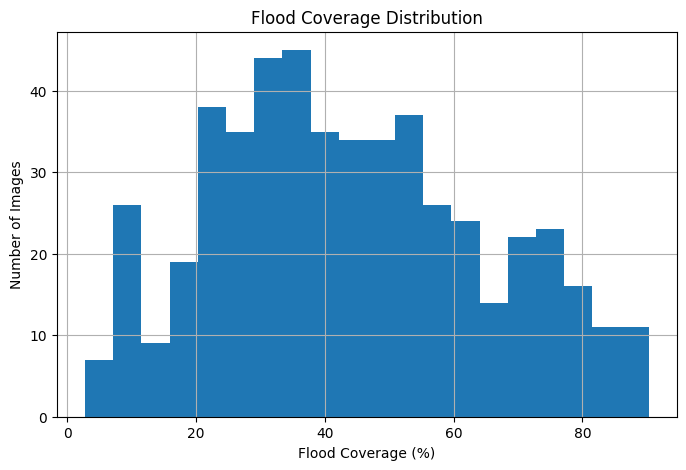

In [24]:
plt.figure(figsize=(8,5))

plt.hist(
    coverage_df["FloodCoverage(%)"],
    bins=20
)

plt.xlabel("Flood Coverage (%)")
plt.ylabel("Number of Images")
plt.title("Flood Coverage Distribution")

plt.grid(True)

plt.show()

Flood Severity Classification

In [31]:
def severity(coverage):

    if coverage < 20:
        return "Low"

    elif coverage < 50:
        return "Moderate"

    else:
        return "High"

coverage_df["SegmentationSeverity"] = coverage_df[
    "FloodCoverage(%)"
].apply(severity)

coverage_df.head()

,Image,FloodPixels,TotalPixels,FloodCoverage(%),SegmentationSeverity
0,1.png,70641,262144,26.95,Moderate
1,1012.png,82054,262144,31.30,Moderate
2,1015.png,151394,262144,57.75,High
3,1024.png,87189,262144,33.26,Moderate
4,1028.png,11228,262144,4.28,Low


Save Final Evidence Table

In [32]:
final_path = os.path.join(
    RESULT_DIR,
    "Flood_Evidence.csv"
)

coverage_df.to_csv(
    final_path,
    index=False
)

print("Saved successfully")

Saved successfully


Upload an Image

In [27]:
from google.colab import files

uploaded = files.upload()

Saving Flood_905.jpg to Flood_905.jpg


Run SegFormer on the Uploaded Image

In [28]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

image_name = list(uploaded.keys())[0]

image = Image.open(image_name).convert("RGB")

inputs = processor(
    images=image,
    return_tensors="pt"
)

pixel_values = inputs["pixel_values"].to(device)

model.eval()

with torch.no_grad():

    outputs = model(pixel_values=pixel_values)

logits = outputs.logits

logits = F.interpolate(
    logits,
    size=image.size[::-1],   # (height, width)
    mode="bilinear",
    align_corners=False
)

prediction = torch.argmax(logits, dim=1).squeeze().cpu().numpy()

Display the Result

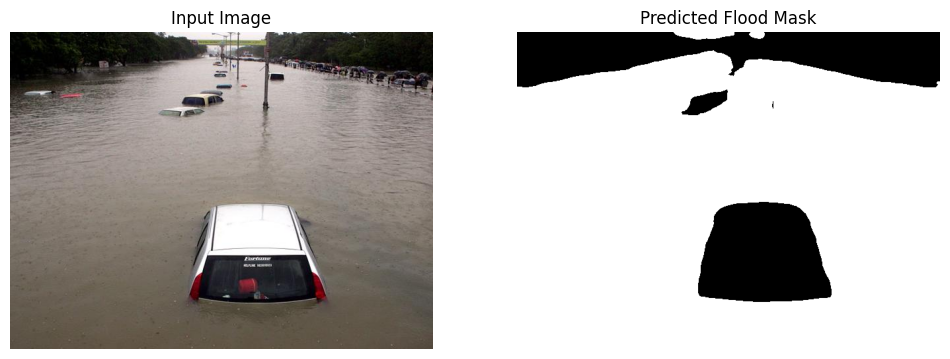

In [29]:
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(prediction, cmap="gray")
plt.title("Predicted Flood Mask")
plt.axis("off")

plt.show()

Calculate Flood Coverage

In [34]:
import torch
import torch.nn.functional as F

# -----------------------------
# Compute confidence
# -----------------------------
with torch.no_grad():

    # Softmax probabilities
    probabilities = F.softmax(outputs.logits, dim=1)

    # Resize to original image size
    probabilities = F.interpolate(
        probabilities,
        size=image.size[::-1],
        mode="bilinear",
        align_corners=False
    )

    # Predicted mask
    predicted_mask = probabilities.argmax(dim=1).squeeze().cpu().numpy()

    # Maximum probability of each pixel
    max_probabilities = probabilities.max(dim=1)[0].squeeze().cpu().numpy()

# -----------------------------
# Flood statistics
# -----------------------------
flood_pixels = (predicted_mask == 1).sum()
total_pixels = predicted_mask.size

coverage = (flood_pixels / total_pixels) * 100

# -----------------------------
# Segmentation Confidence
# Average confidence over predicted flood pixels
# -----------------------------
if flood_pixels > 0:
    confidence = max_probabilities[predicted_mask == 1].mean() * 100
else:
    confidence = max_probabilities.mean() * 100

# -----------------------------
# Severity
# -----------------------------
if coverage < 20:
    severity = "Low"
elif coverage < 50:
    severity = "Moderate"
else:
    severity = "High"

# -----------------------------
# Print Results
# -----------------------------
print("=" * 45)
print(f"Flood Pixels              : {flood_pixels}")
print(f"Total Pixels              : {total_pixels}")
print(f"Flood Coverage            : {coverage:.2f}%")
print(f"Segmentation Severity     : {severity}")
print(f"Segmentation Confidence   : {confidence:.2f}%")
print("=" * 45)

Flood Pixels              : 243887
Total Pixels              : 307200
Flood Coverage            : 79.39%
Segmentation Severity     : High
Segmentation Confidence   : 98.63%
